<a href="https://colab.research.google.com/github/camsmugereski/BU-OMDS-Capstone/blob/main/OMDS_ModC1_Week3_Smugereski_Cameron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3 Jupyter Notebook – Linear Regression 3
## Feature Selection and Dimension Reduction for Credit Risk Analysis

### Project Overview

For Week 3, I am continuing to use the Credit Risk dataset from my capstone project. I am keeping `loan_amnt` as the target variable so I can compare the results with the regression models from Weeks 1 and 2.

In Week 2, regularization did not improve the model very much, so this week I want to see whether selecting a smaller group of predictors or reducing the number of dimensions improves the model.

I will compare four approaches:

- Forward selection
- Backward selection
- Principal Component Regression (PCR)
- Partial Least Squares Regression (PLSR)

The main question I am looking at is:

**Can feature selection or dimension reduction improve the prediction of loan amount compared with a standard linear regression model?**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import statsmodels.api as sm

pd.set_option('display.max_columns', None)

In [ ]:
uploaded = files.upload()

Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv


In [ ]:
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("File loaded:", file_name)
print("Dataset shape:", df.shape)

df.head()

File loaded: credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
target = 'loan_amnt'

continuous_features = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_int_rate',
    'cb_person_cred_hist_length'
]

categorical_features = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

model_columns = continuous_features + categorical_features + [target]

data = df[model_columns].copy()

print("Rows before removing missing values:", len(data))

data = data.dropna()

print("Rows after removing missing values:", len(data))

data.head()

Rows before removing missing values: 32581
Rows after removing missing values: 28638


,person_age,person_income,person_emp_length,loan_int_rate,cb_person_cred_hist_length,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file,loan_amnt
0,22,59000,123.0,16.02,3,RENT,PERSONAL,D,Y,35000
1,21,9600,5.0,11.14,2,OWN,EDUCATION,B,N,1000
2,25,9600,1.0,12.87,3,MORTGAGE,MEDICAL,C,N,5500
3,23,65500,4.0,15.23,2,RENT,MEDICAL,C,N,35000
4,24,54400,8.0,14.27,4,RENT,MEDICAL,C,Y,35000


## Feature Selection

I am using the same variables as Week 2 so the results are easier to compare across the different regression methods.

The target is `loan_amnt`, and I am using borrower characteristics such as income, age, employment length, interest rate, credit history, home ownership, loan intent, loan grade, and previous default history as predictors.

I am continuing to leave out `loan_percent_income` because of the target leakage issue I found in Week 1.

In [ ]:
X = data[continuous_features + categorical_features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            'continuous',
            StandardScaler(),
            continuous_features
        ),
        (
            'categorical',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

feature_names = [
    name.replace('continuous__', '')
        .replace('categorical__', '')
    for name in feature_names
]

X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Training observations:", len(X_train_df))
print("Testing observations:", len(X_test_df))
print("Number of predictors after encoding:", len(feature_names))

X_train_df.head()

Training observations: 22910
Testing observations: 5728
Number of predictors after encoding: 20


,person_age,person_income,person_emp_length,loan_int_rate,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_Y
14324,-0.433402,0.585476,-0.668943,0.208282,-0.694413,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5698,-0.748527,1.273643,-0.430388,-0.120305,-0.942866,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
22936,0.984656,-0.485007,-0.907498,-1.509050,0.796310,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
23963,0.511970,0.019649,2.432272,-0.978971,0.796310,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5750,-0.275840,-0.633346,-0.668943,1.544328,-0.942866,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


## Data Preprocessing

Before running the models, I standardized the continuous variables and converted the categorical variables into dummy variables.

I used the same training and testing split for all of the models so that their performance can be compared fairly.

After preprocessing, I will first use forward and backward selection to determine which individual predictors are most useful. I will then use PCR and PLSR to see whether combining the predictors into a smaller number of components works better.

In [ ]:
baseline_model = LinearRegression()

baseline_model.fit(
    X_train_df,
    y_train
)

baseline_train_pred = baseline_model.predict(
    X_train_df
)

baseline_test_pred = baseline_model.predict(
    X_test_df
)

baseline_train_r2 = r2_score(
    y_train,
    baseline_train_pred
)

baseline_test_r2 = r2_score(
    y_test,
    baseline_test_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_test_pred
    )
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_test_pred
)

print("Baseline Linear Regression")
print("--------------------------")
print(f"Training R²: {baseline_train_r2:.4f}")
print(f"Testing R²:  {baseline_test_r2:.4f}")
print(f"Test RMSE:   {baseline_rmse:.2f}")
print(f"Test MAE:    {baseline_mae:.2f}")

Baseline Linear Regression
--------------------------
Training R²: 0.1112
Testing R²:  0.1418
Test RMSE:   5874.65
Test MAE:    4606.90


## Baseline Linear Regression

I started with a regular linear regression model again so I have a baseline for comparison.

Since the same predictors were used in Week 2, I expect these results to be similar. The main goal this week is to see whether selecting certain predictors or reducing the number of dimensions can improve on this baseline.

## Forward Selection

Forward selection starts with no predictors and adds them one at a time.

At each step, I test the predictors that have not already been selected and add the one that produces the best improvement in the model. I am using AIC to decide which predictor should be added.

A lower AIC indicates a better balance between model fit and complexity. I stop adding variables when adding another predictor no longer lowers the AIC.

In [ ]:
def forward_selection(X, y):
    remaining = list(X.columns)
    selected = []

    current_aic = np.inf

    while remaining:
        aic_candidates = []

        for candidate in remaining:
            features = selected + [candidate]

            X_model = sm.add_constant(
                X[features]
            )

            model = sm.OLS(
                y,
                X_model
            ).fit()

            aic_candidates.append(
                (model.aic, candidate)
            )

        aic_candidates.sort()

        best_aic, best_candidate = aic_candidates[0]

        if best_aic < current_aic:
            selected.append(best_candidate)
            remaining.remove(best_candidate)
            current_aic = best_aic
        else:
            break

    return selected, current_aic


forward_features, forward_aic = forward_selection(
    X_train_df,
    y_train
)

print("Forward Selection")
print("-----------------")
print("Number of selected features:", len(forward_features))
print("Final AIC:", round(forward_aic, 2))

print("\nSelected Features:")

for feature in forward_features:
    print(feature)

Forward Selection
-----------------
Number of selected features: 14
Final AIC: 463387.58

Selected Features:
person_income
loan_int_rate
person_home_ownership_RENT
loan_grade_C
person_emp_length
person_home_ownership_OWN
loan_grade_D
loan_grade_F
loan_grade_G
loan_intent_HOMEIMPROVEMENT
loan_grade_E
loan_grade_B
person_age
cb_person_cred_hist_length


In [ ]:
forward_model = LinearRegression()

forward_model.fit(
    X_train_df[forward_features],
    y_train
)

forward_train_pred = forward_model.predict(
    X_train_df[forward_features]
)

forward_test_pred = forward_model.predict(
    X_test_df[forward_features]
)

forward_train_r2 = r2_score(
    y_train,
    forward_train_pred
)

forward_test_r2 = r2_score(
    y_test,
    forward_test_pred
)

forward_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        forward_test_pred
    )
)

forward_mae = mean_absolute_error(
    y_test,
    forward_test_pred
)

print("Forward Selection Model")
print("-----------------------")
print(f"Training R²: {forward_train_r2:.4f}")
print(f"Testing R²:  {forward_test_r2:.4f}")
print(f"Test RMSE:   {forward_rmse:.2f}")
print(f"Test MAE:    {forward_mae:.2f}")

Forward Selection Model
-----------------------
Training R²: 0.1111
Testing R²:  0.1417
Test RMSE:   5875.13
Test MAE:    4607.59


## Backward Selection

Backward selection takes the opposite approach. Instead of starting with no predictors, I start with all of them.

I then remove the predictor with the highest p-value one at a time. I continue until all remaining predictors have a p-value below 0.05.

I want to compare the variables selected by this method with the ones chosen through forward selection.

In [ ]:
def backward_selection(X, y, significance_level=0.05):

    selected = list(X.columns)

    while True:

        X_model = sm.add_constant(
            X[selected]
        )

        model = sm.OLS(
            y,
            X_model
        ).fit()

        p_values = model.pvalues.drop(
            'const'
        )

        highest_p = p_values.max()

        if highest_p > significance_level:

            remove_feature = p_values.idxmax()

            selected.remove(
                remove_feature
            )

        else:
            break

    return selected


backward_features = backward_selection(
    X_train_df,
    y_train
)

print("Backward Selection")
print("------------------")

print(
    "Number of selected features:",
    len(backward_features)
)

print("\nSelected Features:")

for feature in backward_features:
    print(feature)

Backward Selection
------------------
Number of selected features: 13

Selected Features:
person_age
person_income
person_emp_length
loan_int_rate
cb_person_cred_hist_length
person_home_ownership_OWN
person_home_ownership_RENT
loan_intent_HOMEIMPROVEMENT
loan_grade_B
loan_grade_D
loan_grade_E
loan_grade_F
loan_grade_G


In [ ]:
backward_model = LinearRegression()

backward_model.fit(
    X_train_df[backward_features],
    y_train
)

backward_train_pred = backward_model.predict(
    X_train_df[backward_features]
)

backward_test_pred = backward_model.predict(
    X_test_df[backward_features]
)

backward_train_r2 = r2_score(
    y_train,
    backward_train_pred
)

backward_test_r2 = r2_score(
    y_test,
    backward_test_pred
)

backward_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        backward_test_pred
    )
)

backward_mae = mean_absolute_error(
    y_test,
    backward_test_pred
)

print("Backward Selection Model")
print("------------------------")

print(
    f"Training R²: {backward_train_r2:.4f}"
)

print(
    f"Testing R²:  {backward_test_r2:.4f}"
)

print(
    f"Test RMSE:   {backward_rmse:.2f}"
)

print(
    f"Test MAE:    {backward_mae:.2f}"
)

Backward Selection Model
------------------------
Training R²: 0.1111
Testing R²:  0.1416
Test RMSE:   5875.47
Test MAE:    4607.62


In [ ]:
selection_comparison = pd.DataFrame({
    'Feature': feature_names,
    'Forward Selected': [
        feature in forward_features
        for feature in feature_names
    ],
    'Backward Selected': [
        feature in backward_features
        for feature in feature_names
    ]
})

selection_comparison

,Feature,Forward Selected,Backward Selected
0,person_age,True,True
1,person_income,True,True
2,person_emp_length,True,True
3,loan_int_rate,True,True
4,cb_person_cred_hist_length,True,True
5,person_home_ownership_OTHER,False,False
6,person_home_ownership_OWN,True,True
7,person_home_ownership_RENT,True,True
8,loan_intent_EDUCATION,False,False
9,loan_intent_HOMEIMPROVEMENT,True,True


## Principal Component Regression (PCR)

Next, I used Principal Component Regression. Instead of selecting individual predictors, PCR uses PCA to combine the original predictors into a smaller number of principal components.

I used cross-validation to determine how many components should be included in the regression model. This lets me test whether I can reduce the number of dimensions in the dataset without losing too much predictive information.

In [ ]:
max_components = min(
    X_train_df.shape[1],
    20
)

component_range = range(
    1,
    max_components + 1
)

pcr_cv_rmse = []

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for n_components in component_range:

    pca = PCA(
        n_components=n_components
    )

    X_pca = pca.fit_transform(
        X_train_df
    )

    model = LinearRegression()

    scores = cross_val_score(
        model,
        X_pca,
        y_train,
        cv=cv,
        scoring='neg_mean_squared_error'
    )

    rmse = np.sqrt(
        -scores.mean()
    )

    pcr_cv_rmse.append(rmse)

best_pcr_components = list(
    component_range
)[
    np.argmin(pcr_cv_rmse)
]

print(
    "Best number of PCR components:",
    best_pcr_components
)

print(
    "Lowest cross-validation RMSE:",
    round(min(pcr_cv_rmse), 2)
)

Best number of PCR components: 20
Lowest cross-validation RMSE: 6040.17


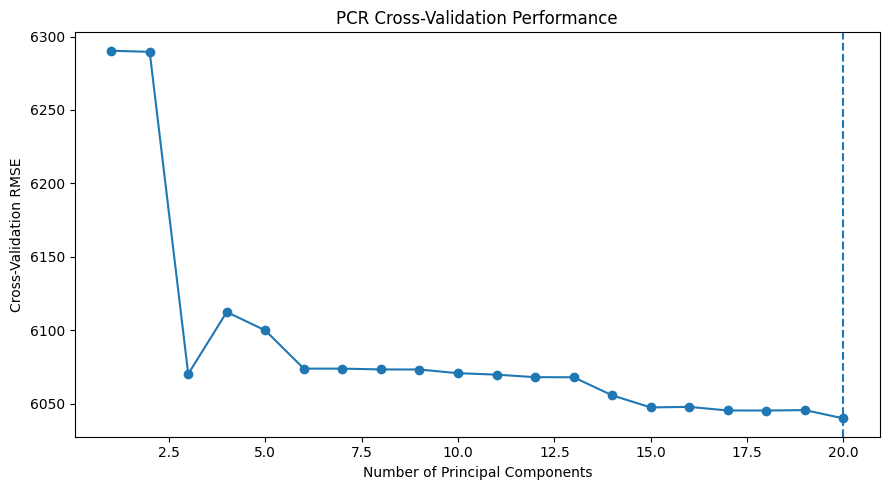

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(component_range),
    pcr_cv_rmse,
    marker='o'
)

plt.axvline(
    best_pcr_components,
    linestyle='--'
)

plt.xlabel(
    'Number of Principal Components'
)

plt.ylabel(
    'Cross-Validation RMSE'
)

plt.title(
    'PCR Cross-Validation Performance'
)

plt.tight_layout()
plt.show()

In [ ]:
pca = PCA(
    n_components=best_pcr_components
)

X_train_pca = pca.fit_transform(
    X_train_df
)

X_test_pca = pca.transform(
    X_test_df
)

pcr_model = LinearRegression()

pcr_model.fit(
    X_train_pca,
    y_train
)

pcr_train_pred = pcr_model.predict(
    X_train_pca
)

pcr_test_pred = pcr_model.predict(
    X_test_pca
)

pcr_train_r2 = r2_score(
    y_train,
    pcr_train_pred
)

pcr_test_r2 = r2_score(
    y_test,
    pcr_test_pred
)

pcr_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        pcr_test_pred
    )
)

pcr_mae = mean_absolute_error(
    y_test,
    pcr_test_pred
)

pcr_variance = (
    pca.explained_variance_ratio_.sum()
)

print("Principal Component Regression")
print("------------------------------")

print(
    "Components:",
    best_pcr_components
)

print(
    f"Variance explained by components: "
    f"{pcr_variance:.4f}"
)

print(
    f"Training R²: {pcr_train_r2:.4f}"
)

print(
    f"Testing R²:  {pcr_test_r2:.4f}"
)

print(
    f"Test RMSE:   {pcr_rmse:.2f}"
)

print(
    f"Test MAE:    {pcr_mae:.2f}"
)

Principal Component Regression
------------------------------
Components: 20
Variance explained by components: 1.0000
Training R²: 0.1112
Testing R²:  0.1418
Test RMSE:   5874.65
Test MAE:    4606.90


## Partial Least Squares Regression (PLSR)

The final method I tested was Partial Least Squares Regression.

PCR creates components based only on the variation in the predictor variables. PLSR is different because it creates components while also considering the relationship between the predictors and the target variable.

Because of this, PLSR may be able to create useful components with fewer dimensions than PCR. I used cross-validation again to choose the number of components.

In [ ]:
max_pls_components = min(
    15,
    X_train_df.shape[1]
)

pls_component_range = range(
    1,
    max_pls_components + 1
)

pls_cv_rmse = []

for n_components in pls_component_range:

    pls = PLSRegression(
        n_components=n_components,
        scale=False
    )

    scores = cross_val_score(
        pls,
        X_train_df,
        y_train,
        cv=cv,
        scoring='neg_mean_squared_error'
    )

    rmse = np.sqrt(
        -scores.mean()
    )

    pls_cv_rmse.append(rmse)

best_pls_components = list(
    pls_component_range
)[
    np.argmin(pls_cv_rmse)
]

print(
    "Best number of PLSR components:",
    best_pls_components
)

print(
    "Lowest cross-validation RMSE:",
    round(min(pls_cv_rmse), 2)
)

Best number of PLSR components: 14
Lowest cross-validation RMSE: 6040.52


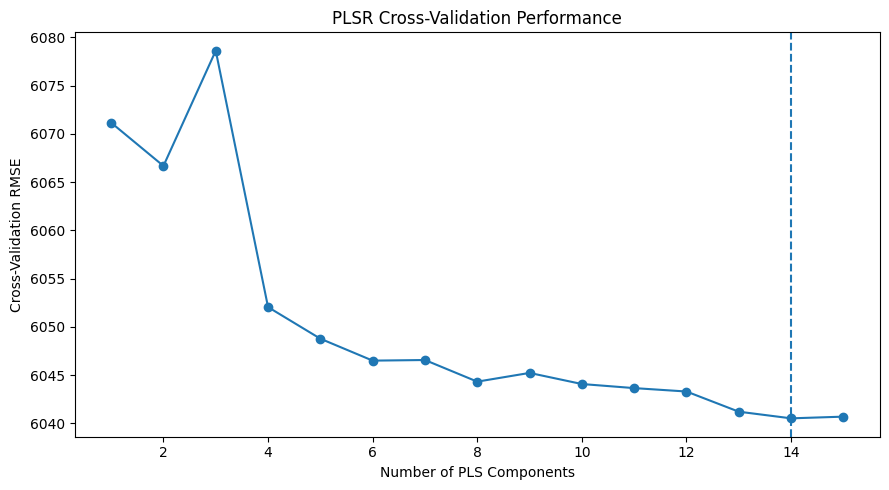

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(pls_component_range),
    pls_cv_rmse,
    marker='o'
)

plt.axvline(
    best_pls_components,
    linestyle='--'
)

plt.xlabel(
    'Number of PLS Components'
)

plt.ylabel(
    'Cross-Validation RMSE'
)

plt.title(
    'PLSR Cross-Validation Performance'
)

plt.tight_layout()
plt.show()

In [ ]:
pls_model = PLSRegression(
    n_components=best_pls_components,
    scale=False
)

pls_model.fit(
    X_train_df,
    y_train
)

pls_train_pred = (
    pls_model
    .predict(X_train_df)
    .ravel()
)

pls_test_pred = (
    pls_model
    .predict(X_test_df)
    .ravel()
)

pls_train_r2 = r2_score(
    y_train,
    pls_train_pred
)

pls_test_r2 = r2_score(
    y_test,
    pls_test_pred
)

pls_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        pls_test_pred
    )
)

pls_mae = mean_absolute_error(
    y_test,
    pls_test_pred
)

print(
    "Partial Least Squares Regression"
)

print(
    "--------------------------------"
)

print(
    "Components:",
    best_pls_components
)

print(
    f"Training R²: {pls_train_r2:.4f}"
)

print(
    f"Testing R²:  {pls_test_r2:.4f}"
)

print(
    f"Test RMSE:   {pls_rmse:.2f}"
)

print(
    f"Test MAE:    {pls_mae:.2f}"
)

Partial Least Squares Regression
--------------------------------
Components: 14
Training R²: 0.1110
Testing R²:  0.1410
Test RMSE:   5877.48
Test MAE:    4610.22


## Model Comparison

Now I can compare the feature selection and dimension reduction methods with the original linear regression model.

I am mainly looking at test R², RMSE, and MAE to determine which approach predicts loan amount the best. I am also comparing training and testing R² to check for overfitting.

For the selection methods, I am interested in whether using fewer predictors can produce similar or better results. For PCR and PLSR, I am looking at whether a smaller number of components can capture enough information to maintain or improve prediction accuracy.

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Forward Selection',
        'Backward Selection',
        'PCR',
        'PLSR'
    ],

    'Train R²': [
        baseline_train_r2,
        forward_train_r2,
        backward_train_r2,
        pcr_train_r2,
        pls_train_r2
    ],

    'Test R²': [
        baseline_test_r2,
        forward_test_r2,
        backward_test_r2,
        pcr_test_r2,
        pls_test_r2
    ],

    'Test RMSE': [
        baseline_rmse,
        forward_rmse,
        backward_rmse,
        pcr_rmse,
        pls_rmse
    ],

    'Test MAE': [
        baseline_mae,
        forward_mae,
        backward_mae,
        pcr_mae,
        pls_mae
    ]
})

results['R² Gap'] = abs(
    results['Train R²'] -
    results['Test R²']
)

results.round(4)

,Model,Train R²,Test R²,Test RMSE,Test MAE,R² Gap
0,Linear Regression,0.1112,0.1418,5874.6482,4606.8955,0.0306
1,Forward Selection,0.1111,0.1417,5875.1330,4607.5918,0.0306
2,Backward Selection,0.1111,0.1416,5875.4686,4607.6180,0.0305
3,PCR,0.1112,0.1418,5874.6482,4606.8955,0.0306
4,PLSR,0.1110,0.1410,5877.4825,4610.2181,0.0300


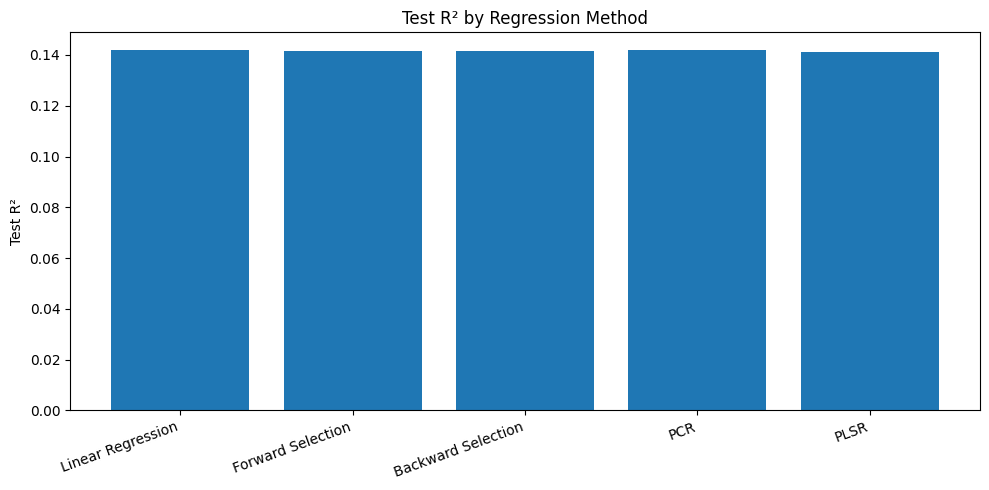

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    results['Model'],
    results['Test R²']
)

plt.ylabel('Test R²')

plt.title(
    'Test R² by Regression Method'
)

plt.xticks(
    rotation=20,
    ha='right'
)

plt.tight_layout()
plt.show()

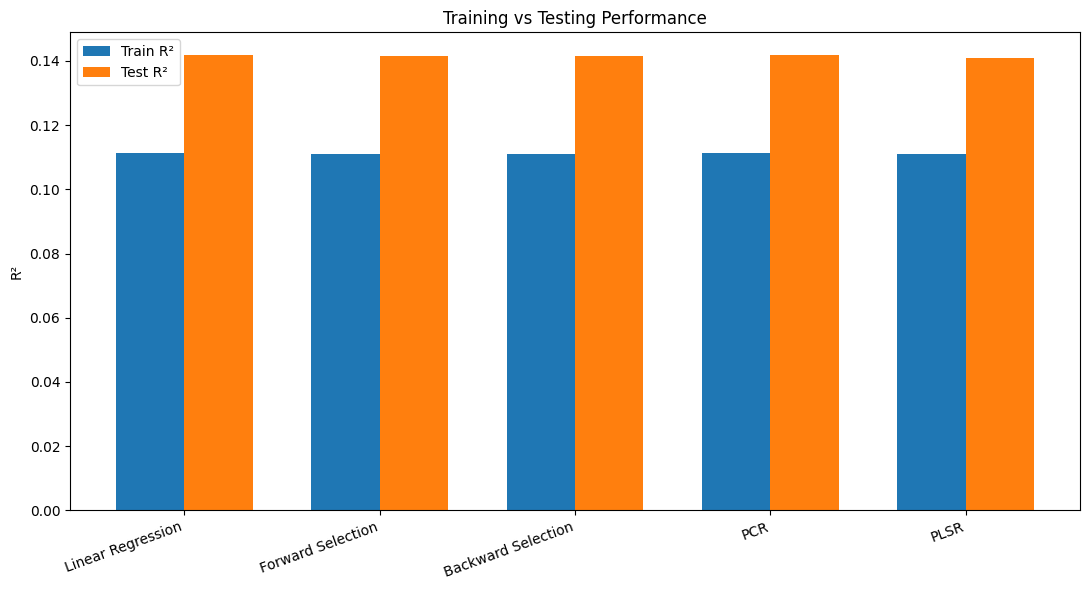

In [ ]:
plt.figure(figsize=(11, 6))

x = np.arange(
    len(results)
)

width = 0.35

plt.bar(
    x - width / 2,
    results['Train R²'],
    width,
    label='Train R²'
)

plt.bar(
    x + width / 2,
    results['Test R²'],
    width,
    label='Test R²'
)

plt.xticks(
    x,
    results['Model'],
    rotation=20,
    ha='right'
)

plt.ylabel('R²')

plt.title(
    'Training vs Testing Performance'
)

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_r2_model = results.loc[
    results['Test R²'].idxmax(),
    'Model'
]

best_rmse_model = results.loc[
    results['Test RMSE'].idxmin(),
    'Model'
]

smallest_gap_model = results.loc[
    results['R² Gap'].idxmin(),
    'Model'
]

print("WEEK 3 MODEL SUMMARY")
print("=" * 60)

print(
    "Highest Test R²:",
    best_r2_model
)

print(
    "Lowest Test RMSE:",
    best_rmse_model
)

print(
    "Smallest Train/Test R² Gap:",
    smallest_gap_model
)

print("\nFeature Selection")
print("-" * 60)

print(
    "Original predictors:",
    len(feature_names)
)

print(
    "Forward selection predictors:",
    len(forward_features)
)

print(
    "Backward selection predictors:",
    len(backward_features)
)

print("\nDimension Reduction")
print("-" * 60)

print(
    "Best PCR components:",
    best_pcr_components
)

print(
    "Best PLSR components:",
    best_pls_components
)

WEEK 3 MODEL SUMMARY
Highest Test R²: Linear Regression
Lowest Test RMSE: Linear Regression
Smallest Train/Test R² Gap: PLSR

Feature Selection
------------------------------------------------------------
Original predictors: 20
Forward selection predictors: 14
Backward selection predictors: 13

Dimension Reduction
------------------------------------------------------------
Best PCR components: 20
Best PLSR components: 14


## Week 3 Conclusions

For Week 3, I compared forward selection, backward selection, PCR, and PLSR with a regular linear regression model. I wanted to see if selecting fewer predictors or reducing the number of dimensions could improve the prediction of loan amount.

### Baseline Linear Regression

The baseline linear regression had a training R² of 0.1112 and a test R² of 0.1418. The test RMSE was 5,874.65 and the MAE was 4,606.90. These results were the same as Week 2 since I used the same predictors and continued to leave out `loan_percent_income`.

### Forward Selection

Forward selection kept 14 of the original 20 predictors and produced a test R² of 0.1417. The RMSE was 5,875.13 and the MAE was 4,607.59.

The performance was almost identical to the baseline model even though six predictors were removed. This was interesting because it shows that some of the variables could be removed without having much effect on the model's predictions.

### Backward Selection

Backward selection reduced the model even further and kept 13 of the 20 predictors. It produced a test R² of 0.1416, an RMSE of 5,875.47, and an MAE of 4,607.62.

Forward and backward selection chose many of the same variables. Both kept age, income, employment length, interest rate, credit history length, home ownership, home improvement loan intent, and several loan grade variables. One difference was that forward selection kept loan grade C while backward selection removed it.

Even though backward selection used fewer predictors, its performance was still extremely close to both forward selection and the full linear regression model.

### Principal Component Regression

For PCR, cross-validation selected 20 principal components. These components explained 100% of the variance in the predictors.

Since there were originally 20 predictors after encoding, PCR ended up keeping all 20 components. Because no dimensions were actually removed, the PCR model produced the same results as the baseline linear regression, with a test R² of 0.1418, an RMSE of 5,874.65, and an MAE of 4,606.90.

I expected PCR to reduce the number of dimensions, so this result was somewhat unexpected. In this case, reducing the number of components caused worse cross-validation performance, so PCR did not provide an advantage over regular linear regression.

### Partial Least Squares Regression

PLSR selected 14 components through cross-validation. It produced a training R² of 0.1110 and a test R² of 0.1410. The RMSE was 5,877.48 and the MAE was 4,610.22.

PLSR successfully reduced the number of dimensions, but its predictive performance was slightly worse than the baseline model. It did have the smallest difference between training and testing R² at 0.0300, although the differences between all of the models were very small.

### Overfitting

None of the models showed strong evidence of overfitting. The training and testing R² values were fairly similar across all five models. PLSR had the smallest train/test gap, but it also had the lowest test R².

This suggests that overfitting is probably not the main reason for the relatively low R² values. Instead, the predictors included in these models may simply have limited ability to explain variation in loan amount.

### Overall Conclusion

Overall, regular linear regression had the highest test R² and lowest RMSE, although the differences between the models were very small. Neither PCR nor PLSR improved prediction accuracy.

The feature selection results were more useful. Forward selection reduced the model from 20 to 14 predictors, and backward selection reduced it to 13, while producing almost the same results as the full model. This shows that several predictors can be removed without losing much predictive information.

Across Weeks 2 and 3, I am seeing that changing the linear regression method does not substantially improve the prediction of loan amount once `loan_percent_income` is removed. Week 2 showed that regularization did not improve the model, and Week 3 showed a similar result for feature selection and dimension reduction. This suggests that the bigger limitation may be the information available in the predictors rather than the specific type of linear regression being used.